**4.0 Evaluation metric for classification**

**4.1 Overview & preparation**

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [4]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

In [5]:
# !wget $data -O data-week-3.csv

In [6]:
df = pd.read_csv('data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_variables = df.columns[df.dtypes == 'str']

for c in categorical_variables:
    df[c] = df[c].str.lower().str.replace(' ', '_')
    
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [7]:
df

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,0
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.50,0
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,1
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,0
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-resvb,male,0,yes,yes,24,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,yes,mailed_check,84.80,1990.50,0
7039,2234-xaduh,female,0,yes,yes,72,yes,yes,fiber_optic,no,...,yes,no,yes,yes,one_year,yes,credit_card_(automatic),103.20,7362.90,0
7040,4801-jzazl,female,0,yes,yes,11,no,no_phone_service,dsl,yes,...,no,no,no,no,month-to-month,yes,electronic_check,29.60,346.45,0
7041,8361-ltmkd,male,1,yes,no,4,yes,yes,fiber_optic,no,...,no,no,no,no,month-to-month,yes,mailed_check,74.40,306.60,1


In [8]:
categorical_variables

Index(['customerid', 'gender', 'partner', 'dependents', 'phoneservice',
       'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup',
       'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies',
       'contract', 'paperlessbilling', 'paymentmethod', 'totalcharges',
       'churn'],
      dtype='str')

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [10]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = ['gender', 'seniorcitizen', 'partner', 'dependents',
       'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']

In [11]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(max_iter=3000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [12]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

**4.2 Accuracy and Dummy Model**

In [13]:
len(y_val)

1409

In [14]:
from sklearn.metrics import accuracy_score

In [15]:
threshold = np.linspace(0, 1, 21)
scores = []

for t in threshold:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.513
0.10 0.608
0.15 0.662
0.20 0.703
0.25 0.735
0.30 0.759
0.35 0.764
0.40 0.781
0.45 0.791
0.50 0.803
0.55 0.802
0.60 0.796
0.65 0.789
0.70 0.766
0.75 0.742
0.80 0.729
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


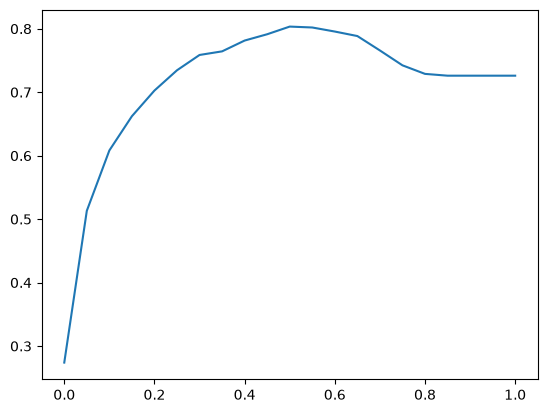

In [16]:
plt.plot(threshold, scores)

In [17]:
from collections import Counter

In [18]:
Counter(y_pred >= 0.5)

Counter({np.False_: 1094, np.True_: 315})

In [19]:
Counter(y_pred >= 1)

Counter({np.False_: 1409})

In [20]:
1 - y_val.mean()

np.float64(0.7260468417317246)

**4.3 Confusion Table**

In [21]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [22]:
predict_positive = (y_pred >= 0.5)
predict_negative = (y_pred < 0.5)

In [23]:
tp = (actual_positive & predict_positive).sum()
tp

np.int64(212)

In [24]:
fp = (actual_negative & predict_positive).sum()
fp

np.int64(103)

In [25]:
tn = (actual_negative & predict_negative).sum()
tn

np.int64(920)

In [26]:
fn = (actual_positive & predict_negative).sum()
fn

np.int64(174)

In [27]:
tn+tp+fn+fp

np.int64(1409)

In [28]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

In [29]:
confusion_matrix

array([[920, 103],
       [174, 212]])

In [30]:
Counter(actual_positive)

Counter({np.False_: 1023, np.True_: 386})

In [31]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

In [32]:
accuracy=(tn+tp)/confusion_matrix.sum()
accuracy
# result as seen before

np.float64(0.8034066713981547)

**4.4 Precision and Recall**

In [33]:
p = tp / (tp + fp)
p

np.float64(0.6730158730158731)

In [34]:
r = tp / (tp + fn)
r

np.float64(0.5492227979274611)

**4.5 ROC Curves**

**TPR & FPR**

In [35]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5492227979274611)

In [36]:
fpr = fp / (tp + tn)
fpr

np.float64(0.09098939929328621)

In [37]:
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (actual_positive & predict_positive).sum()
    fp = (actual_negative & predict_positive).sum()
    tn = (actual_negative & predict_negative).sum()
    fn = (actual_positive & predict_negative).sum()

    scores.append((float(t), float(tn), float(tp), float(fn), float(fp)))

In [38]:
scores

[(0.0, 0.0, 386.0, 0.0, 1023.0),
 (0.01, 128.0, 385.0, 1.0, 895.0),
 (0.02, 219.0, 383.0, 3.0, 804.0),
 (0.03, 273.0, 382.0, 4.0, 750.0),
 (0.04, 315.0, 382.0, 4.0, 708.0),
 (0.05, 345.0, 378.0, 8.0, 678.0),
 (0.06, 370.0, 377.0, 9.0, 653.0),
 (0.07, 399.0, 374.0, 12.0, 624.0),
 (0.08, 435.0, 371.0, 15.0, 588.0),
 (0.09, 466.0, 370.0, 16.0, 557.0),
 (0.1, 491.0, 366.0, 20.0, 532.0),
 (0.11, 511.0, 364.0, 22.0, 512.0),
 (0.12, 526.0, 361.0, 25.0, 497.0),
 (0.13, 541.0, 360.0, 26.0, 482.0),
 (0.14, 563.0, 358.0, 28.0, 460.0),
 (0.15, 580.0, 353.0, 33.0, 443.0),
 (0.16, 592.0, 350.0, 36.0, 431.0),
 (0.17, 609.0, 349.0, 37.0, 414.0),
 (0.18, 623.0, 346.0, 40.0, 400.0),
 (0.19, 644.0, 345.0, 41.0, 379.0),
 (0.2, 651.0, 339.0, 47.0, 372.0),
 (0.21, 668.0, 335.0, 51.0, 355.0),
 (0.22, 688.0, 327.0, 59.0, 335.0),
 (0.23, 703.0, 324.0, 62.0, 320.0),
 (0.24, 714.0, 319.0, 67.0, 309.0),
 (0.25, 721.0, 314.0, 72.0, 302.0),
 (0.26, 734.0, 313.0, 73.0, 289.0),
 (0.27, 746.0, 308.0, 78.0, 277.0),
 (0

In [39]:
columns = ('threshold', 'tn', 'tp', 'fn', 'fp')
df_scores = pd.DataFrame(scores, columns=columns)

In [40]:
df_scores

,threshold,tn,tp,fn,fp
0,0.00,0.0,386.0,0.0,1023.0
1,0.01,128.0,385.0,1.0,895.0
2,0.02,219.0,383.0,3.0,804.0
3,0.03,273.0,382.0,4.0,750.0
4,0.04,315.0,382.0,4.0,708.0
...,...,...,...,...,...
96,0.96,1023.0,0.0,386.0,0.0
97,0.97,1023.0,0.0,386.0,0.0
98,0.98,1023.0,0.0,386.0,0.0
99,0.99,1023.0,0.0,386.0,0.0


In [41]:
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

In [42]:
df_scores[::10]

,threshold,tn,tp,fn,fp,tpr,fpr
0,0.0,0.0,386.0,0.0,1023.0,1.000000,1.000000
10,0.1,491.0,366.0,20.0,532.0,0.948187,0.520039
20,0.2,651.0,339.0,47.0,372.0,0.878238,0.363636
30,0.3,776.0,293.0,93.0,247.0,0.759067,0.241447
40,0.4,848.0,253.0,133.0,175.0,0.655440,0.171065
50,0.5,920.0,212.0,174.0,103.0,0.549223,0.100684
60,0.6,970.0,151.0,235.0,53.0,0.391192,0.051808
70,0.7,1010.0,69.0,317.0,13.0,0.178756,0.012708
80,0.8,1023.0,4.0,382.0,0.0,0.010363,0.000000
90,0.9,1023.0,0.0,386.0,0.0,0.000000,0.000000


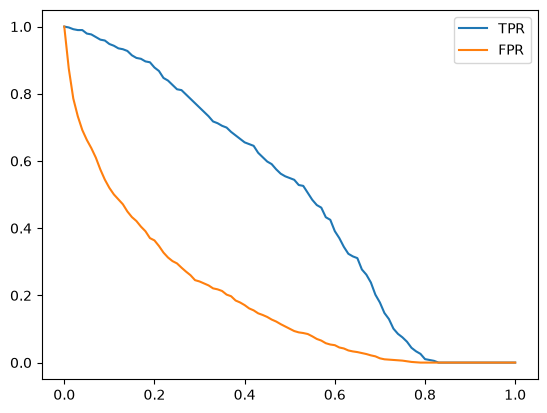

In [43]:
plt.plot(df_scores.threshold, df_scores.tpr, label='TPR')
plt.plot(df_scores.threshold, df_scores.fpr, label='FPR')
plt.legend()

**Random model**

In [44]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [45]:
y_rand = y_rand.round(3)
y_rand

array([0.417, 0.72 , 0.   , ..., 0.774, 0.334, 0.089], shape=(1409,))

In [46]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [47]:
# Accuracy for this random model is 50% which is because we just generated some random values as the prediction or model output. 
# So since it is random, it only makes sense that the accuracy is 50%

In [48]:
def tpr_fpr_df(y_val, y_pred):
    thresholds = np.linspace(0, 1, 101)
    scores = []
    
    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)
    
        tp = (actual_positive & predict_positive).sum()
        fp = (actual_negative & predict_positive).sum()
        tn = (actual_negative & predict_negative).sum()
        fn = (actual_positive & predict_negative).sum()
    
        scores.append((float(t), float(tn), float(tp), float(fn), float(fp)))

    columns = ('threshold', 'tn', 'tp', 'fn', 'fp')
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [49]:
df_rand = tpr_fpr_df(y_val, y_rand)

In [50]:
df_rand[::10]

,threshold,tn,tp,fn,fp,tpr,fpr
0,0.0,0.0,386.0,0.0,1023.0,1.000000,1.000000
10,0.1,100.0,347.0,39.0,923.0,0.898964,0.902248
20,0.2,201.0,307.0,79.0,822.0,0.795337,0.803519
30,0.3,299.0,276.0,110.0,724.0,0.715026,0.707722
40,0.4,399.0,237.0,149.0,624.0,0.613990,0.609971
50,0.5,504.0,203.0,183.0,519.0,0.525907,0.507331
60,0.6,613.0,162.0,224.0,410.0,0.419689,0.400782
70,0.7,721.0,120.0,266.0,302.0,0.310881,0.295210
80,0.8,816.0,79.0,307.0,207.0,0.204663,0.202346
90,0.9,922.0,40.0,346.0,101.0,0.103627,0.098729


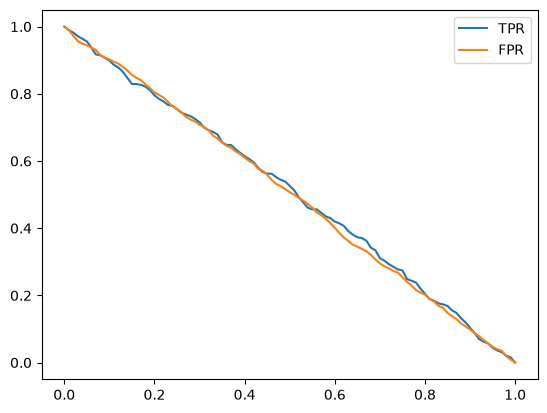

In [51]:
plt.plot(df_rand.threshold, df_rand.tpr, label='TPR')
plt.plot(df_rand.threshold, df_rand.fpr, label='FPR')
plt.legend()

**Ideal Model**

In [52]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

In [53]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])

In [54]:
Counter(y_ideal)

Counter({np.int64(0): 1023, np.int64(1): 386})

In [55]:
y_ideal_pred = np.linspace(0, 1, len(y_val))
y_ideal_pred

array([0.00000000e+00, 7.10227273e-04, 1.42045455e-03, ...,
       9.98579545e-01, 9.99289773e-01, 1.00000000e+00], shape=(1409,))

In [56]:
1-(y_val == 1).mean()

np.float64(0.7260468417317246)

In [57]:
accuracy_score((y_ideal_pred >= 0.726), y_ideal)

1.0

In [58]:
df_ideal = tpr_fpr_df(y_ideal, y_ideal_pred)

In [59]:
df_ideal[::10]

,threshold,tn,tp,fn,fp,tpr,fpr
0,0.0,0.0,386.0,0.0,1023.0,1.000000,1.000000
10,0.1,141.0,386.0,0.0,882.0,1.000000,0.862170
20,0.2,282.0,386.0,0.0,741.0,1.000000,0.724340
30,0.3,423.0,386.0,0.0,600.0,1.000000,0.586510
40,0.4,564.0,386.0,0.0,459.0,1.000000,0.448680
50,0.5,704.0,386.0,0.0,319.0,1.000000,0.311828
60,0.6,845.0,386.0,0.0,178.0,1.000000,0.173998
70,0.7,986.0,386.0,0.0,37.0,1.000000,0.036168
80,0.8,1023.0,282.0,104.0,0.0,0.730570,0.000000
90,0.9,1023.0,141.0,245.0,0.0,0.365285,0.000000


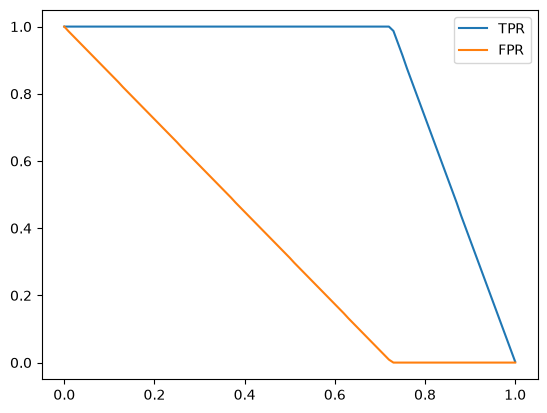

In [60]:
plt.plot(df_ideal.threshold, df_ideal.tpr, label='TPR')
plt.plot(df_ideal.threshold, df_ideal.fpr, label='FPR')
plt.legend()

In [61]:
# The above is an ideal model

**Putting everything together**

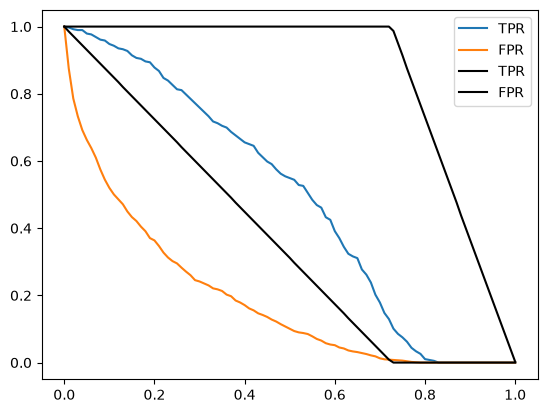

In [62]:
plt.plot(df_scores.threshold, df_scores.tpr, label='TPR')
plt.plot(df_scores.threshold, df_scores.fpr, label='FPR')

# plt.plot(df_rand.threshold, df_rand.tpr, label='TPR')
# plt.plot(df_rand.threshold, df_rand.fpr, label='FPR')

plt.plot(df_ideal.threshold, df_ideal.tpr, label='TPR', color='black')
plt.plot(df_ideal.threshold, df_ideal.fpr, label='FPR', color='black')
plt.legend()

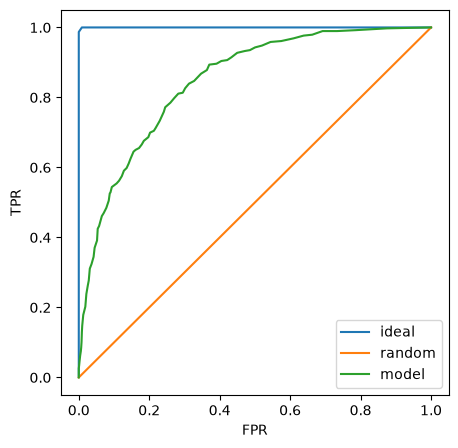

In [63]:
plt.figure(figsize=(5, 5))
plt.plot(df_ideal.fpr, df_ideal.tpr, label='ideal')
# plt.plot(df_rand.fpr, df_rand.tpr, label='random')
plt.plot([0, 1], [0, 1], label='random')  #we know the random model is like a straight line so let's represent it as straight
plt.plot(df_scores.fpr, df_scores.tpr, label='model')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.legend()

In [64]:
# The model curve has to be close to the ideal curve to have a good model

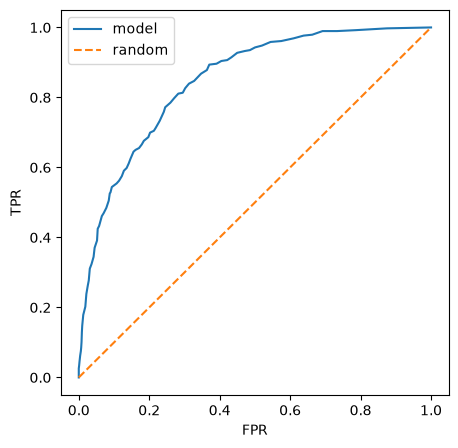

In [65]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='model')
plt.plot([0, 1], [0, 1], label='random', linestyle='--') 

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()
# This is the roc curve

In [66]:
from sklearn.metrics import roc_curve

In [67]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

In [68]:
fpr

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 9.77517107e-04,
       9.77517107e-04, 1.95503421e-03, 1.95503421e-03, 3.91006843e-03,
       3.91006843e-03, 4.88758553e-03, 4.88758553e-03, 5.86510264e-03,
       5.86510264e-03, 6.84261975e-03, 6.84261975e-03, 7.82013685e-03,
       7.82013685e-03, 8.79765396e-03, 8.79765396e-03, 9.77517107e-03,
       9.77517107e-03, 1.07526882e-02, 1.07526882e-02, 1.27077224e-02,
       1.27077224e-02, 1.36852395e-02, 1.36852395e-02, 1.56402737e-02,
       1.56402737e-02, 1.66177908e-02, 1.66177908e-02, 1.75953079e-02,
       1.75953079e-02, 1.85728250e-02, 1.85728250e-02, 1.95503421e-02,
       1.95503421e-02, 2.15053763e-02, 2.15053763e-02, 2.34604106e-02,
       2.34604106e-02, 2.44379277e-02, 2.44379277e-02, 2.54154448e-02,
       2.54154448e-02, 2.63929619e-02, 2.63929619e-02, 2.73704790e-02,
       2.73704790e-02, 2.83479961e-02, 2.83479961e-02, 2.93255132e-02,
       2.93255132e-02, 3.12805474e-02, 3.12805474e-02, 3.32355816e-02,
      

In [69]:
thresholds

array([       inf, 0.82783682, 0.78734433, 0.78213892, 0.77678246,
       0.77556958, 0.76805325, 0.76649171, 0.75376446, 0.75361833,
       0.75330049, 0.75234973, 0.75049171, 0.74975369, 0.73114302,
       0.7301314 , 0.72704494, 0.72687141, 0.71806784, 0.71718494,
       0.7080951 , 0.70718251, 0.70592555, 0.70358825, 0.70131133,
       0.69727536, 0.69469005, 0.6938705 , 0.69359417, 0.69241555,
       0.69208498, 0.69191452, 0.6918316 , 0.69077752, 0.6859838 ,
       0.68395801, 0.68315732, 0.68220636, 0.67779008, 0.67738154,
       0.67675339, 0.67548445, 0.67356135, 0.67344573, 0.66874201,
       0.66740318, 0.66569316, 0.66169458, 0.66161458, 0.66124492,
       0.65925277, 0.65891863, 0.65827088, 0.65768938, 0.64962979,
       0.64767703, 0.63754068, 0.63586205, 0.63382721, 0.63118404,
       0.62968385, 0.62847976, 0.62814336, 0.6274949 , 0.62356674,
       0.62147649, 0.62037143, 0.62023252, 0.61707777, 0.6169724 ,
       0.61204095, 0.6116006 , 0.60910085, 0.60581514, 0.60463

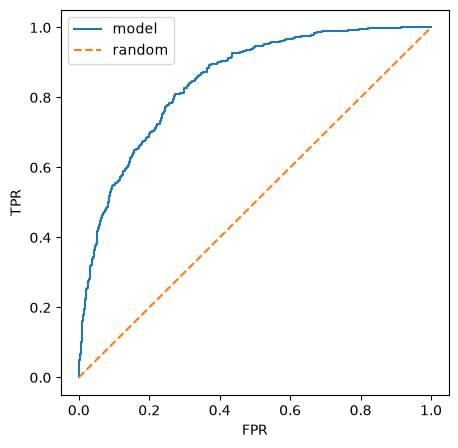

In [70]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='model')
plt.plot([0, 1], [0, 1], label='random', linestyle='--') 

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

**4.6 AUC**

In [71]:
from sklearn.metrics import auc

In [72]:
auc(fpr, tpr)  #the one computed from sklearn

0.846286701208981

In [73]:
auc(df_scores.fpr, df_scores.tpr)  #the one we compueted manually

0.8460309260075264

In [74]:
# Both are pretty close.

In [75]:
# Instead of using roc_curve to first get fpr and tpr before using auc, we can do all in one using:
from sklearn.metrics import roc_auc_score

In [76]:
roc_auc_score(y_val, y_pred)

0.846286701208981

In [77]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [78]:
import random

In [79]:
neg_idx = random.randint(0, len(neg) - 1)
pos_idx = random.randint(0, len(pos) - 1)

In [80]:
pos[pos_idx] > neg[neg_idx]

np.True_

In [81]:
# n = len(y_val)
n = 100000
success = 0

for i in range(n):
    neg_idx = random.randint(0, len(neg) - 1)
    pos_idx = random.randint(0, len(pos) - 1)

    if pos[pos_idx] > neg[neg_idx]:
        success += 1
# print(success)
print(success / n)

0.84612


In [82]:
# using a vectorized approach with numpy,

In [83]:
n= 50000
np.random.seed(1)
neg_idx = np.random.randint(0, len(neg), size=n)
pos_idx = np.random.randint(0, len(pos), size=n)

(pos[pos_idx] > neg[neg_idx]).mean()

np.float64(0.84644)

**4.7 Cross-Validation**

In [114]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical+numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=True)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=5000)
    model.fit(X_train, y_train)

    return dv, model

In [85]:
def predict(df_val, dv, model):
    dicts = df_val[categorical+numerical].to_dict(orient='records')
    X_val = dv.transform(dicts)

    y_pred = model.predict_proba(X_val)[:,1]
    return y_pred

In [88]:
from sklearn.model_selection import KFold

In [92]:
kfold = KFold(n_splits = 10, shuffle=True, random_state=1)
train_idx, val_idx = next(kfold.split(df_full_train)) #using next() only takes one iteration index pair. kfold splits into 
                                                      # index pairs(for train and val) the number of times specified by the n_splits parameter
                                                      # next() starts with the first time and then each time it is called again, it returns the next item

In [95]:
train_idx.shape, val_idx.shape

((5070,), (564,))

In [97]:
len(df_full_train)

5634

In [98]:
# By specifying n_splits=10, we split df_full_train into then and then take 9 folds for the train_idx and one fold for val_idx

In [102]:
!pip install tqdm

In [103]:
from tqdm.auto import tqdm

In [107]:
scores = []
for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=10):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.churn.values
    y_val = df_val.churn.values
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    score = roc_auc_score(y_val, y_pred)
    scores.append(score)

  0%|          | 0/10 [00:00<?, ?it/s]

In [108]:
scores

[0.849720910261915,
 0.8422803217821782,
 0.8585784761556733,
 0.8334046580528351,
 0.8247518610421837,
 0.8411088911088912,
 0.8430478671442526,
 0.8252925363693864,
 0.8459167037201719,
 0.8611475244529595]

In [109]:
# the above are the auc scores for all the 10 pair of folds

In [115]:
n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 1, 5, 10], total=6):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train.churn.values
        y_val = df_val.churn.values
        
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
    
        score = roc_auc_score(y_val, y_pred)
        scores.append(score)
        
    print("C=%s %.3f +- %.3f" % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/6 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.008
C=0.1 0.842 +- 0.007
C=1 0.842 +- 0.007
C=5 0.842 +- 0.007
C=10 0.842 +- 0.007


In [117]:
# From the about we can use C=1.0 or others having same value of mean and std.

In [119]:
y_full_train = df_full_train.churn.values
dv, model = train(df_full_train, y_full_train, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)

In [120]:
auc

0.8584682093449033

In [ ]:
 # That is slightly better than the cross-validation average - a small difference like this is normal

In [123]:
import time
for i in tqdm(range(25), total=25):
    print(auc)
    time.sleep(5)
# just used this to test tqdm. 5 * 25 = 125 seconds so the total time to complete the iterations should be 2 mins 5 secs and tqdm got that right.

  0%|          | 0/25 [00:00<?, ?it/s]

0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
0.8584682093449033
